# When should mosquito control start? A dengue SIR model for Colombo, calibrated with MCMC

[One-paragraph summary, written last: the problem, the model, the key result and how it was verified.]

In [2]:
# Setup: imports, random seed and data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

SEED = 42                      # every random result in this notebook uses this seed
rng = np.random.default_rng(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__)

# Use the local copy when the repository is cloned; download it on a fresh Colab runtime.
DATA_URL = "https://raw.githubusercontent.com/geethsenaviratne/dengue-sir-mcmc-colombo/main/data/colombo_2017.csv"
try:
    cases = pd.read_csv("../data/colombo_2017.csv")
except FileNotFoundError:
    cases = pd.read_csv(DATA_URL)

assert len(cases) == 52 and cases["week"].tolist() == list(range(1, 53)), "expected 52 consecutive weeks of 2017"
cases.head()

numpy 2.5.5 | pandas 3.1.1


,year,week,start_date,end_date,cases
0,2017,1,2016-12-31,2017-01-06,342
1,2017,2,2017-01-07,2017-01-13,531
2,2017,3,2017-01-14,2017-01-20,565
3,2017,4,2017-01-21,2017-01-27,482
4,2017,5,2017-01-28,2017-02-03,417


## 1. Problem and question

In 2017, Colombo district had its largest dengue epidemic in the weekly records that begin in 2007. Reported cases rose from a few hundred a week early in the year to 1,972 in the week beginning 15 July, then collapsed to below 300 a week by September. Mosquito-control campaigns are often launched once cases are already rising, so the timing of control is a decision health authorities face every season.

**Question:** if mosquito control had cut transmission by 20%, starting a given number of weeks before the peak, how much lower and later would the 2017 peak have been? Answers are reported with 95% credible intervals.

## 2. Model, assumptions and equations

**Model.** An SIR (susceptible–infected–recovered) model of Colombo district, with time $t$ measured in weeks of 2017:

$$\frac{dS}{dt} = -\beta(t)\,\frac{S I}{N}, \qquad \frac{dI}{dt} = \beta(t)\,\frac{S I}{N} - \gamma I, \qquad \frac{dR}{dt} = \gamma I$$

**Drop in transmission.** Transmission falls by a fraction $\delta$ around week $\tau$, through a smooth switch of width $w$:

$$\beta(t) = \beta\left[1 - \delta\,\sigma\!\left(\frac{t-\tau}{w}\right)\right], \qquad \sigma(x) = \frac{1}{1+e^{-x}}$$

**Mosquito control.** Control cuts transmission by a fraction $c$ from week $a$ for $d$ weeks:

$$\beta_{\text{control}}(t) = \beta(t)\left[1 - c\left(\sigma\!\left(\tfrac{t-a}{w}\right) - \sigma\!\left(\tfrac{t-a-d}{w}\right)\right)\right]$$

**Link to the data.** The expected reported cases in week $k$ are the new infections in that week plus a constant background $b$:

$$\mu_k = \int_{\text{week } k} \beta(t)\,\frac{S I}{N}\,dt \; + \; b$$

**Basic reproduction number** before the drop: $R_0 = \beta / \gamma$. The epidemic grows when $R_0 > 1$ and dies out when $R_0 < 1$.

| Symbol | Meaning | Units | Value / range | Source |
|---|---|---|---|---|
| $S, I, R$ | Susceptible, infected and recovered people | people | $S + I + R = N$ | — |
| $N$ | Colombo district population, mid-2017 | people | 2,480,000 | Census 2012 and 2024, interpolated [3] |
| $\beta$ | Transmission rate before the drop | per week | fitted | MCMC (section 3) |
| $\gamma$ | Recovery rate, 7 ÷ infectious period | per week | 7 / 6.5 = 1.077 | Infectious for about 6.5 days [2] |
| $\delta$ | Fraction by which transmission drops | — | fitted, 0–1 | MCMC |
| $\tau$ | Week in which the drop happens | week of 2017 | fitted | MCMC |
| $w$ | Width of the smooth switch | weeks | 0.5 | Assumption |
| $I_0$ | Infected people at the start of week 12 | people | fitted | MCMC |
| $b$ | Background reported cases | cases per week | fitted | MCMC |
| $c, a, d$ | Control: cut, start week, duration | —, week, weeks | scenario inputs | Section 5 |
| $k$ | Negative-binomial dispersion (noise in the counts) | — | fitted | MCMC |

**Assumptions**
1. Colombo district is one well-mixed population of fixed size $N$. Births, deaths and travel are ignored over the 31 weeks modelled.
2. The mosquito stage of transmission is folded into $\beta$; mosquitoes are not modelled explicitly. A coupled human–mosquito model is the stretch goal.
3. Reported cases are new modelled infections plus a constant background. Because $S$ stays close to $N$, a reporting fraction would only rescale $I_0$, so it is not estimated separately.
4. The wave ends because transmission falls (for example, the end of the monsoon or control activities). This is captured by one smooth drop at week $\tau$.
5. $\gamma$ is fixed from the literature. Its effect on the results is tested in the sensitivity analysis.
6. The fitting window is weeks 12–42 of 2017. The earlier weeks are the tail of the previous season.

**Concepts used:**
- Population and epidemic models (the SIR model)
- Numerical ODE solvers and their error order (RK4, section 3.1)
- MCMC and the Metropolis algorithm (section 3.2)
- Monte Carlo integration (credible intervals, section 5)

## 3. Implementation

### 3.1 SIR model and RK4 solver

**RK4 method.** The equations give the rate of change at each moment. RK4 turns them into a curve by stepping forward in time with step $h$. Each step evaluates the slope four times ($k_1 \dots k_4$) and takes a weighted average:

$$y_{n+1} = y_n + \frac{h}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right)$$

Its global error falls as $h^4$, so halving the step makes the error about 16 times smaller. This is checked in section 4.

**Weekly infections.** A fourth variable $C$ counts all infections so far, with $dC/dt = \beta(t) S I / N$. The new infections in a week are $C$ at the end of the week minus $C$ at the start.

**Several runs at once.** Every function accepts NumPy arrays of parameters, so many runs are computed together. The MCMC and the scenario study rely on this.

In [3]:
# Fixed inputs
# Colombo district mid-year population, 2017: official estimate (Department of Census and Statistics) [3]
N = 2_480_000

INFECTIOUS_DAYS = 6.5          # infectious to mosquitoes from ~1.5 days before to ~5 days after symptom onset [2]
GAMMA = 7 / INFECTIOUS_DAYS    # recovery rate (per week)

FIRST_WEEK, LAST_WEEK = 12, 42 # fitting window: the mid-2017 wave (late March to mid-October)
TRANSITION_WEEKS = 0.5         # width w of the smooth switch in transmission (weeks)
STEPS_PER_WEEK = 10            # RK4 time step h = 0.1 week

print(f"N = {N:,} people | gamma = {GAMMA:.3f} per week | window = weeks {FIRST_WEEK}-{LAST_WEEK}")

N = 2,480,000 people | gamma = 1.077 per week | window = weeks 12-42


In [6]:
def smooth_step(x):
    """Logistic switch sigma(x): 0 well before x = 0, 1 well after it."""
    return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))

def transmission_rate(week, p, control=None):
    """beta(t) in infections per week. `week` is the (continuous) week of 2017."""
    beta = p["beta"] * (1 - p["delta"] * smooth_step((week - p["tau"]) / TRANSITION_WEEKS))
    if control is not None:   # mosquito control: cut transmission by a fraction for a number of weeks
        on = (smooth_step((week - control["start"]) / TRANSITION_WEEKS)
              - smooth_step((week - control["start"] - control["weeks"]) / TRANSITION_WEEKS))
        beta = beta * (1 - control["cut"] * on)
    return beta

def sir_rhs(week, y, p, control=None):
    """Right-hand side of the SIR equations. y = [S, I, R, C]; C counts all infections so far."""
    S, I, R, C = y
    new_infections = transmission_rate(week, p, control) * S * I / N
    recoveries = GAMMA * I
    return np.array([-new_infections, new_infections - recoveries, recoveries, new_infections])

def rk4_step(f, t, y, h):
    """One fourth-order Runge-Kutta step of size h for dy/dt = f(t, y)."""
    k1 = f(t, y)
    k2 = f(t + h / 2, y + h / 2 * k1)
    k3 = f(t + h / 2, y + h / 2 * k2)
    k4 = f(t + h, y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def simulate(p, control=None, steps_per_week=STEPS_PER_WEEK, first_week=FIRST_WEEK, last_week=LAST_WEEK):
    """Solve the model from the start of `first_week` to the end of `last_week`.
    Parameters may be numbers or NumPy arrays (one run per array element)."""
    n_weeks = last_week - first_week + 1
    h = 1.0 / steps_per_week
    I0 = np.asarray(p["I0"], dtype=float)
    y = np.array([N - I0, I0, np.zeros_like(I0), np.zeros_like(I0)])
    f = lambda t, y: sir_rhs(t, y, p, control)
    path = [y]
    for k in range(n_weeks * steps_per_week):
        y = rk4_step(f, first_week + k * h, y, h)
        path.append(y)
    path = np.array(path)                                       # shape: (time steps + 1, 4, runs...)
    new_per_week = np.diff(path[::steps_per_week, 3], axis=0)   # infections in each calendar week
    return {
        "week": np.arange(first_week, last_week + 1),
        "expected_cases": new_per_week + np.asarray(p["bg"]),
        "t": first_week + h * np.arange(n_weeks * steps_per_week + 1),
        "S": path[:, 0], "I": path[:, 1], "R": path[:, 2],
    }

**Sanity check.** Hand-picked values, not a fit, show that the model can produce a wave of the right size and shape. The MCMC in section 3.2 replaces them with fitted values and uncertainty.

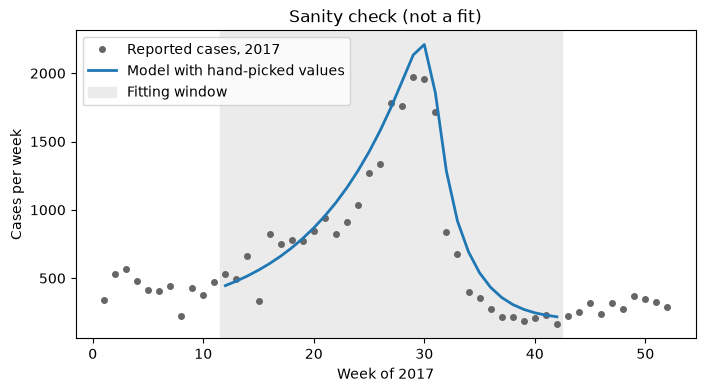

R0 before the drop = 1.11; model peak = 2210 cases in week 30


In [7]:
GUESS = {"beta": 1.20, "delta": 0.40, "tau": 31.5, "I0": 200.0, "bg": 190.0}
run = simulate(GUESS)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cases["week"], cases["cases"], "o", ms=4, color="0.4", label="Reported cases, 2017")
ax.plot(run["week"], run["expected_cases"], "-", lw=2, label="Model with hand-picked values")
ax.axvspan(FIRST_WEEK - 0.5, LAST_WEEK + 0.5, color="0.92", zorder=0, label="Fitting window")
ax.set_xlabel("Week of 2017"); ax.set_ylabel("Cases per week")
ax.set_title("Sanity check (not a fit)"); ax.legend()
plt.show()
print(f"R0 before the drop = {GUESS['beta'] / GAMMA:.2f}; "
      f"model peak = {run['expected_cases'].max():.0f} cases in week {run['week'][run['expected_cases'].argmax()]}")

### 3.2 Calibration with Metropolis MCMC

**Unknowns.** Six numbers are not known in advance and must be estimated from the 2017 data:
$\theta = (\beta, \delta, \tau, I_0, b, k)$.

**Likelihood: how well do $\theta$ explain the data?** The model predicts $\mu_k(\theta)$ cases in week $k$. The observed count $y_k$ is treated as a negative-binomial random number with mean $\mu_k$ and dispersion $k$:

$$P(y_k \mid \theta) = \frac{\Gamma(y_k + k)}{\Gamma(k)\, y_k!}\left(\frac{k}{k+\mu_k}\right)^{k}\left(\frac{\mu_k}{k+\mu_k}\right)^{y_k}, \qquad \operatorname{Var}(y_k) = \mu_k + \frac{\mu_k^2}{k}$$

A Poisson model would force the variance to equal the mean (a standard deviation of about 30 when $\mu = 1000$). Real weekly counts are much noisier: for example, week 15 dips to 332 between 664 and 823. The extra term $\mu^2/k$ allows for this; a small $k$ means noisy data, and a large $k$ means nearly Poisson. The weeks are treated as independent, so the log-likelihood is the sum over the 31 weeks.

**Prior: what values are plausible before seeing the data?** Each parameter has a uniform prior over a wide, plausible range, so the data decide where inside the range it lies:

| Parameter | Range | Reason |
|---|---|---|
| $\beta$ | 0.5 – 3.0 per week | $R_0 = \beta/\gamma$ from about 0.5 to 2.8 |
| $\delta$ | 0 – 0.95 | Anything from no drop to a 95% drop |
| $\tau$ | week 20 – 40 | The drop happens somewhere in the season |
| $I_0$ | 1 – 5,000 | People infected at the start of week 12 |
| $b$ | 0 – 1,000 | Background cases per week |
| $k$ | 1 – 500 | From very noisy to nearly Poisson |

**Posterior (Bayes' theorem).** $p(\theta \mid y) \propto p(y \mid \theta)\, p(\theta)$. It cannot be written down directly, so it is sampled.

**Random-walk Metropolis algorithm [5]:**
1. Start at some $\theta$.
2. Propose a nearby point $\theta^* = \theta + \varepsilon$, with $\varepsilon \sim \mathcal{N}(0, \Sigma)$.
3. Accept it with probability $\min\!\left(1, \; p(\theta^* \mid y) / p(\theta \mid y)\right)$; otherwise stay at $\theta$.
4. Repeat. The visited points are draws from the posterior.

A better fit is always accepted, and a worse fit is sometimes accepted. That is what lets the chain explore the uncertainty instead of only climbing to the single best point.

**Practical choices:**
- **Several chains at once.** 32 chains run in parallel, which is fast because `simulate` is vectorised.
- **Step size inside the MCMC.** The likelihood uses RK4 with $h = 0.25$ week instead of 0.1. Section 4's convergence check shows this changes the weekly cases by less than 0.01, while making the fit 2.5 times faster.
- **Tuning run.** A short pilot run estimates the shape of the posterior. The main run then uses $\Sigma = \frac{2.38^2}{d}\,\mathrm{Cov}(\text{pilot})$, with $d = 6$, the standard scaling for random-walk Metropolis [6]. The main run keeps $\Sigma$ fixed, so it is a valid Metropolis chain.
- **Burn-in.** The first 500 of the 1,500 main-run iterations are discarded, which leaves 32,000 posterior samples.
- **Convergence check.** Gelman–Rubin $\hat{R}$ compares the variance within each chain with the variance between chains. Values below 1.1 mean the chains agree [7].

In [8]:
from scipy.special import gammaln

# Inside the MCMC the RK4 step is h = 0.25 week: 2.5 times faster, and (as Check 3 predicts)
# the weekly cases change by only a few thousandths of a case compared with h = 0.1 week.
MCMC_STEPS_PER_WEEK = 4
rk4_gap = np.max(np.abs(simulate(GUESS, steps_per_week=MCMC_STEPS_PER_WEEK)["expected_cases"] - run["expected_cases"]))
assert rk4_gap < 0.01, f"h = 0.25 week is not accurate enough: {rk4_gap:.4f} cases"
print(f"RK4 with h = 0.25 week differs from h = 0.1 week by at most {rk4_gap:.4f} cases per week")

PARAM_NAMES = ["beta", "delta", "tau", "I0", "bg", "k"]
LOWER = np.array([0.5, 0.00, 20.0,    1.0,    0.0,   1.0])   # uniform prior ranges
UPPER = np.array([3.0, 0.95, 40.0, 5000.0, 1000.0, 500.0])
obs = cases.set_index("week").loc[FIRST_WEEK:LAST_WEEK, "cases"].to_numpy()   # the 31 observed weeks

def to_params(theta):
    """Turn an array of shape (chains, 6) into the parameter dictionary used by simulate()."""
    return {name: theta[:, i] for i, name in enumerate(PARAM_NAMES)}

def log_prior(theta):
    """0 inside the prior ranges, minus infinity outside (uniform priors)."""
    inside = np.all((theta > LOWER) & (theta < UPPER), axis=1)
    return np.where(inside, 0.0, -np.inf)

def log_likelihood(theta, y):
    """Negative-binomial log-likelihood of the weekly counts y, summed over the weeks."""
    mu = simulate(to_params(theta), steps_per_week=MCMC_STEPS_PER_WEEK)["expected_cases"]   # (weeks, chains)
    k = theta[:, 5]
    y = y[:, None]
    ll = (gammaln(y + k) - gammaln(k) - gammaln(y + 1)
          + k * np.log(k / (k + mu)) + y * np.log(mu / (k + mu)))
    return ll.sum(axis=0)

def log_posterior(theta, y):
    """log p(theta | y) up to a constant = log prior + log likelihood."""
    lp = log_prior(theta)
    ok = np.isfinite(lp)
    out = np.full(len(theta), -np.inf)
    if ok.any():                                   # only simulate the chains that are inside the prior
        out[ok] = lp[ok] + log_likelihood(theta[ok], y)
    return out

print("log-posterior at the hand-picked guess (k = 50):",
      log_posterior(np.array([[1.20, 0.40, 31.5, 200.0, 190.0, 50.0]]), obs).round(1))

RK4 with h = 0.25 week differs from h = 0.1 week by at most 0.0039 cases per week
log-posterior at the hand-picked guess (k = 50): [-216.2]


In [15]:
def metropolis(y, start, proposal_cov, n_iter, rng):
    """Random-walk Metropolis, run for several chains at once. start has shape (chains, 6)."""
    n_chains, d = start.shape
    L = np.linalg.cholesky(proposal_cov)                 # to draw correlated Gaussian steps
    theta = start.copy()
    logp = log_posterior(theta, y)
    assert np.all(np.isfinite(logp)), "every chain must start inside the prior"
    samples = np.empty((n_iter, n_chains, d))
    accepted = 0
    for it in range(n_iter):
        proposal = theta + rng.standard_normal((n_chains, d)) @ L.T     # step 2: propose
        logp_new = log_posterior(proposal, y)
        accept = np.log(rng.random(n_chains)) < logp_new - logp           # step 3: accept with prob min(1, ratio)
        theta[accept] = proposal[accept]
        logp[accept] = logp_new[accept]
        accepted += accept.sum()
        samples[it] = theta
    return samples, accepted / (n_iter * n_chains)

def r_hat(chains):
    """Gelman-Rubin statistic for one parameter; chains has shape (iterations, chains)."""
    n = chains.shape[0]
    W = chains.var(axis=0, ddof=1).mean()                # average variance within each chain
    B = n * chains.mean(axis=0).var(ddof=1)              # variance between the chain means
    return np.sqrt(((n - 1) / n * W + B / n) / W)

def calibrate(y, start_guess, rng, n_chains=32, n_pilot=800, n_main=1500, burn=500):
    """Pilot run to tune the proposal, then the main run. Returns kept samples (iterations, chains, 6)."""
    d = len(start_guess)
    first_steps = np.array([0.01, 0.01, 0.1, 10.0, 5.0, 5.0])            # rough step sizes for the pilot
    start = start_guess * (1 + 0.02 * rng.standard_normal((n_chains, d)))  # chains start near the guess
    pilot, acc_pilot = metropolis(y, start, np.diag(first_steps**2), n_pilot, rng)
    tail = pilot[n_pilot // 2:].reshape(-1, d)
    cov = np.cov(tail.T) * 2.38**2 / d + 1e-10 * np.eye(d)               # tuned proposal [6]
    main, acc_main = metropolis(y, pilot[-1], cov, n_main, rng)
    kept = main[burn:]
    rhat = np.array([r_hat(kept[:, :, i]) for i in range(d)])
    return {"samples": kept, "flat": kept.reshape(-1, d), "acceptance": acc_main, "rhat": rhat}

def summarise(fit, truth=None):
    """Table of posterior median and 95% credible interval for each parameter."""
    lo, med, hi = np.percentile(fit["flat"], [2.5, 50, 97.5], axis=0)
    table = pd.DataFrame({"median": med, "2.5%": lo, "97.5%": hi, "R-hat": fit["rhat"]}, index=PARAM_NAMES)
    if truth is not None:
        table.insert(0, "true value", truth)
        table["inside 95%?"] = (lo <= truth) & (truth <= hi)
    return table

START = np.array([1.20, 0.40, 31.5, 200.0, 190.0, 50.0])   # the hand-picked guess, plus k = 50

## 4. Verification

### 4.1 Solver checks

1. **Conservation.** People only move between groups, so $S + I + R$ must equal $N$ at every step.
2. **Analytic result.** With constant $\beta$, dividing $dS/dt$ by $dR/dt$ gives $dS/dR = -(\beta/\gamma)\,S/N$. Integrating gives the exact relation $S(t) = S_0\,e^{-R_0 R(t)/N}$, which the solver must reproduce.
3. **Convergence order.** RK4's error should fall as $h^4$: a slope of about 4 on a log-log plot.
4. **Limiting cases.** With $R_0 < 1$ the number infected must only fall, and a 0% control cut must reproduce the baseline exactly.

In [10]:
# Check 1: conservation of S + I + R = N
drift = np.max(np.abs(run["S"] + run["I"] + run["R"] - N)) / N
assert drift < 1e-12, f"S+I+R drifted from N by {drift:.1e}"
print(f"PASS 1 (conservation): max |S+I+R-N|/N = {drift:.1e}")

PASS 1 (conservation): max |S+I+R-N|/N = 9.4e-16


In [11]:
# Check 2: analytic SIR relation S(t) = S0 * exp(-R0 * R(t) / N) for constant beta
CONST = {"beta": 2.0 * GAMMA, "delta": 0.0, "tau": 0.0, "I0": 50.0, "bg": 0.0}   # R0 = 2
r = simulate(CONST, first_week=0, last_week=40, steps_per_week=20)
S0 = N - CONST["I0"]
S_exact = S0 * np.exp(-(CONST["beta"] / GAMMA) * r["R"] / N)
rel_err = np.max(np.abs(r["S"] - S_exact) / S_exact)
assert rel_err < 1e-6, f"analytic check failed: max relative error {rel_err:.1e}"
print(f"PASS 2 (analytic relation): max relative error = {rel_err:.1e}")

PASS 2 (analytic relation): max relative error = 1.0e-09


PASS 3 (RK4 order): fitted slope = 4.03 (expected 4)


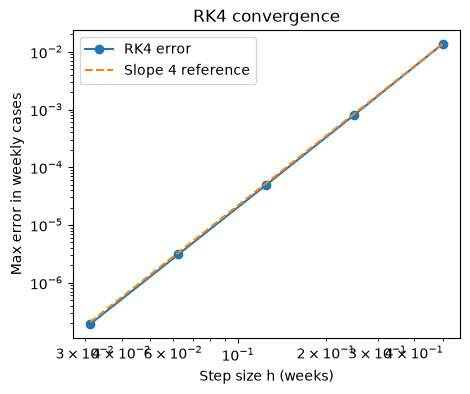

In [12]:
# Check 3: RK4 error falls as h^4 (compared with a very fine reference solution)
CTRL = {"cut": 0.2, "start": 25, "weeks": 6}          # include a control period, so the switches are tested too
steps = np.array([2, 4, 8, 16, 32])
h = 1 / steps
reference = simulate(GUESS, CTRL, steps_per_week=1024)["expected_cases"]
errors = np.array([np.max(np.abs(simulate(GUESS, CTRL, steps_per_week=s)["expected_cases"] - reference))
                   for s in steps])
slope = np.polyfit(np.log(h), np.log(errors), 1)[0]
assert 3.6 < slope < 4.4, f"expected a slope of about 4, got {slope:.2f}"
print(f"PASS 3 (RK4 order): fitted slope = {slope:.2f} (expected 4)")

fig, ax = plt.subplots(figsize=(5, 4))
ax.loglog(h, errors, "o-", label="RK4 error")
ax.loglog(h, errors[0] * (h / h[0]) ** 4, "--", label="Slope 4 reference")
ax.set_xlabel("Step size h (weeks)"); ax.set_ylabel("Max error in weekly cases")
ax.set_title("RK4 convergence"); ax.legend()
plt.show()

In [13]:
# Check 4: limiting cases
LOW = {"beta": 0.8 * GAMMA, "delta": 0.0, "tau": 0.0, "I0": 500.0, "bg": 0.0}     # R0 = 0.8 < 1
low = simulate(LOW)
assert np.all(np.diff(low["I"]) < 0), "with R0 < 1 the number infected should only fall"

no_cut = simulate(GUESS, {"cut": 0.0, "start": 25, "weeks": 6})["expected_cases"]
assert np.array_equal(no_cut, run["expected_cases"]), "a 0% cut must reproduce the baseline exactly"
print("PASS 4 (limiting cases): R0 < 1 dies out, and a 0% cut equals the baseline")

PASS 4 (limiting cases): R0 < 1 dies out, and a 0% cut equals the baseline


### 4.2 Calibration check: recovering known parameters from synthetic data

Before the sampler is trusted with real data, it is tested on data where the answer is known:
1. Choose "true" parameter values.
2. Simulate the epidemic with them and add negative-binomial noise, which creates fake weekly counts.
3. Run exactly the same MCMC on the fake counts.
4. Check that every true value lies inside its 95% credible interval, and that the chains agree ($\hat{R} < 1.1$).

If the sampler or the likelihood had a bug, the true values would fall outside the intervals.

In [16]:
rng_synth = np.random.default_rng(SEED + 1)        # separate seeded generator, so this cell always gives the same result
TRUE = np.array([1.25, 0.45, 31.0, 150.0, 200.0, 40.0])
mu_true = simulate(to_params(TRUE[None, :]))["expected_cases"][:, 0]
k_true = TRUE[5]
y_fake = rng_synth.negative_binomial(k_true, k_true / (k_true + mu_true))   # fake weekly counts with realistic noise

t0 = time.perf_counter()
fit_synth = calibrate(y_fake, START, rng_synth)
print(f"Synthetic fit: {time.perf_counter() - t0:.0f} s, acceptance rate {fit_synth['acceptance']:.2f}")
table_synth = summarise(fit_synth, TRUE)
display(table_synth.round(3))

assert table_synth["inside 95%?"].all(), "a true value fell outside its 95% credible interval"
assert (fit_synth["rhat"] < 1.1).all(), "the chains have not converged (R-hat >= 1.1)"
print("PASS 5 (calibration): all 6 true values recovered inside their 95% intervals; all R-hat < 1.1")

Synthetic fit: 69 s, acceptance rate 0.23


,true value,median,2.5%,97.5%,R-hat,inside 95%?
beta,1.25,1.254,1.228,1.283,1.016,True
delta,0.45,0.463,0.384,0.554,1.013,True
tau,31.00,31.330,30.567,32.149,1.016,True
I0,150.00,128.962,85.884,189.455,1.016,True
bg,200.00,205.249,136.210,266.930,1.010,True
k,40.00,36.893,21.017,60.962,1.013,True


PASS 5 (calibration): all 6 true values recovered inside their 95% intervals; all R-hat < 1.1


## 5. Experiments and results

### 5.1 Calibration to the 2017 Colombo wave

The same sampler is now run on the real weekly counts for weeks 12–42. The output is a set of posterior samples: thousands of parameter combinations that are all consistent with the data, in proportion to how well they fit.

In [17]:
rng_fit = np.random.default_rng(SEED + 2)
t0 = time.perf_counter()
fit = calibrate(obs, START, rng_fit)
print(f"2017 fit: {time.perf_counter() - t0:.0f} s, acceptance rate {fit['acceptance']:.2f}, "
      f"{fit['flat'].shape[0]:,} posterior samples")
table_fit = summarise(fit)
display(table_fit.round(3))
assert (fit["rhat"] < 1.1).all(), "the chains have not converged (R-hat >= 1.1)"

post = fit["flat"]                                   # posterior samples, used from here on
R0 = post[:, 0] / GAMMA
R_after = R0 * (1 - post[:, 1])
def ci(x): return np.percentile(x, [50, 2.5, 97.5])
print("R0 before the drop:  median {:.3f}  (95% CrI {:.3f} to {:.3f})".format(*ci(R0)))
print("R after the drop:    median {:.3f}  (95% CrI {:.3f} to {:.3f})".format(*ci(R_after)))

2017 fit: 15 s, acceptance rate 0.26, 32,000 posterior samples


,median,2.5%,97.5%,R-hat
beta,1.181,1.164,1.200,1.008
delta,0.532,0.430,0.661,1.008
tau,31.821,31.211,32.424,1.010
I0,238.028,182.144,299.938,1.008
bg,188.836,151.952,227.096,1.013
k,44.731,24.511,76.347,1.018


R0 before the drop:  median 1.096  (95% CrI 1.080 to 1.114)
R after the drop:    median 0.513  (95% CrI 0.373 to 0.622)


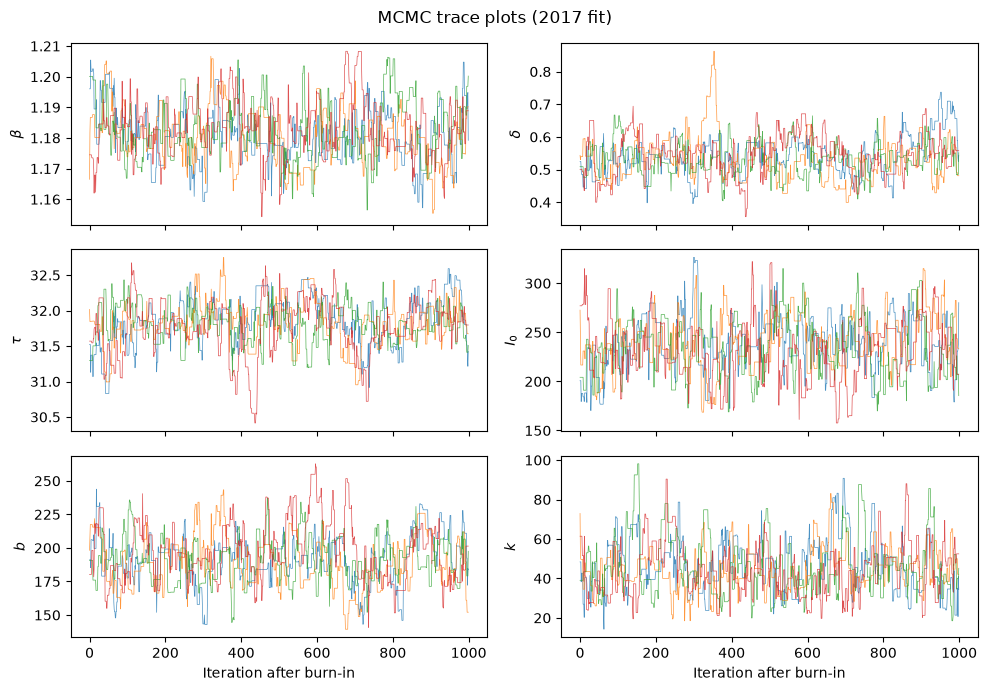

In [18]:
# Trace plots: each line is one chain (4 of the 32 shown). Well-mixed chains look like overlapping "fuzzy caterpillars".
labels = [r"$\beta$", r"$\delta$", r"$\tau$", r"$I_0$", r"$b$", r"$k$"]
fig, axes = plt.subplots(3, 2, figsize=(10, 7), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(fit["samples"][:, :4, i], lw=0.5, alpha=0.8)
    ax.set_ylabel(labels[i])
axes[-1, 0].set_xlabel("Iteration after burn-in"); axes[-1, 1].set_xlabel("Iteration after burn-in")
fig.suptitle("MCMC trace plots (2017 fit)")
plt.tight_layout(); plt.show()

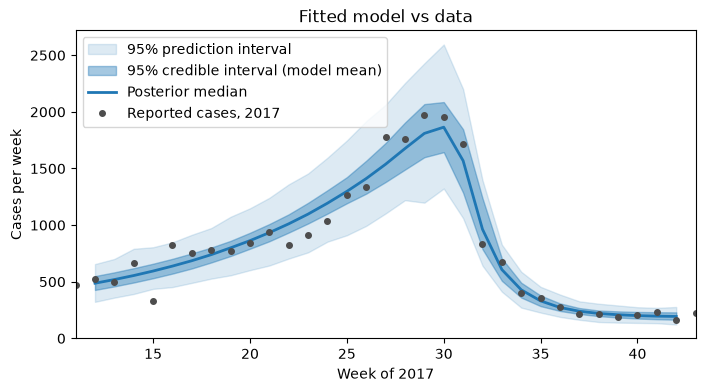

97% of the 31 observed weeks fall inside the 95% prediction interval


In [19]:
# Posterior predictive check: does the fitted model, with its uncertainty, reproduce the observed weeks?
rng_ppc = np.random.default_rng(SEED + 3)
draws = post[rng_ppc.choice(len(post), size=500, replace=False)]
mu = simulate(to_params(draws))["expected_cases"]                     # (weeks, 500)
k = draws[:, 5]
y_rep = rng_ppc.negative_binomial(k, k / (k + mu))                     # new fake data from each draw
mu_lo, mu_med, mu_hi = np.percentile(mu, [2.5, 50, 97.5], axis=1)
pred_lo, pred_hi = np.percentile(y_rep, [2.5, 97.5], axis=1)
weeks = np.arange(FIRST_WEEK, LAST_WEEK + 1)
coverage = np.mean((obs >= pred_lo) & (obs <= pred_hi))

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(weeks, pred_lo, pred_hi, color="C0", alpha=0.15, label="95% prediction interval")
ax.fill_between(weeks, mu_lo, mu_hi, color="C0", alpha=0.4, label="95% credible interval (model mean)")
ax.plot(weeks, mu_med, color="C0", lw=2, label="Posterior median")
ax.plot(cases["week"], cases["cases"], "o", ms=4, color="0.3", label="Reported cases, 2017")
ax.set_xlim(FIRST_WEEK - 1, LAST_WEEK + 1)
ax.set_xlabel("Week of 2017"); ax.set_ylabel("Cases per week"); ax.set_title("Fitted model vs data")
ax.legend(); plt.show()
print(f"{coverage:.0%} of the 31 observed weeks fall inside the 95% prediction interval")

### 5.2 The question: what if mosquito control had started earlier?

**Scenario.** From week $a$ onwards, mosquito control cuts transmission by $c = 20\%$, so $\beta(t)$ is multiplied by 0.8 for the rest of the season. The start week is set $k$ weeks before each posterior draw's own baseline peak, for $k = 0, 1, \dots, 8$. Each scenario is run for 2,000 posterior draws, so every result comes with a 95% credible interval.

**Outputs for each draw:**
- **Peak reduction**: how much lower the highest week is, as a percentage of the baseline peak.
- **Peak shift**: how many weeks earlier (negative) or later (positive) the peak comes.
- **Cases averted**: the percentage of reported cases in weeks 12–42 that would not have happened.

In [20]:
def control_scenario(draws, weeks_before, cut=0.2, duration=np.inf):
    """Run baseline and controlled epidemics for each posterior draw; return peak reduction (%),
    peak shift (weeks) and cases averted (%). Control starts `weeks_before` weeks before each draw's peak."""
    p = to_params(draws)
    base = simulate(p)["expected_cases"]                              # (weeks, draws)
    peak_week = FIRST_WEEK + base.argmax(axis=0)                      # each draw's own baseline peak
    ctrl = simulate(p, {"cut": cut, "start": peak_week - weeks_before, "weeks": duration})["expected_cases"]
    reduction = 100 * (base.max(axis=0) - ctrl.max(axis=0)) / base.max(axis=0)
    shift = ctrl.argmax(axis=0) - base.argmax(axis=0)
    averted = 100 * (base.sum(axis=0) - ctrl.sum(axis=0)) / base.sum(axis=0)
    return reduction, shift, averted

def fmt(x):
    """Median with its 95% credible interval, as text."""
    med, lo, hi = np.percentile(x, [50, 2.5, 97.5])
    return f"{med:.1f} ({lo:.1f} to {hi:.1f})"

rng_scen = np.random.default_rng(SEED + 4)
draws = post[rng_scen.choice(len(post), size=2000, replace=False)]

rows, median_reduction = [], []
for k in range(9):
    red, shift, averted = control_scenario(draws, k)
    median_reduction.append(np.median(red))
    rows.append({"weeks before peak": k, "peak reduction %": fmt(red),
                 "peak shift (weeks)": f"{np.median(shift):+.0f}", "cases averted %": fmt(averted)})
results = pd.DataFrame(rows).set_index("weeks before peak")
display(results)

assert np.all(np.diff(median_reduction) > 0), "starting earlier should always lower the peak more"
print("Starting earlier lowers the peak more at every step (checked).")

,peak reduction %,peak shift (weeks),cases averted %
weeks before peak,,,
0,12.1 (8.7 to 15.5),-1,9.0 (7.6 to 13.0)
1,18.7 (15.2 to 23.0),-2,13.2 (11.4 to 17.6)
2,25.2 (21.6 to 30.0),-3,17.6 (15.6 to 22.5)
3,31.2 (27.1 to 36.5),-4,22.2 (20.0 to 27.4)
4,36.7 (32.3 to 42.3),-5,26.9 (24.3 to 32.1)
5,41.7 (37.0 to 47.5),-6,31.4 (28.5 to 36.6)
6,46.3 (41.3 to 52.2),-7,35.7 (32.7 to 41.0)
7,50.5 (45.2 to 56.5),-8,39.9 (36.7 to 45.2)
8,54.2 (48.8 to 60.3),-9,43.9 (40.5 to 49.2)


Starting earlier lowers the peak more at every step (checked).


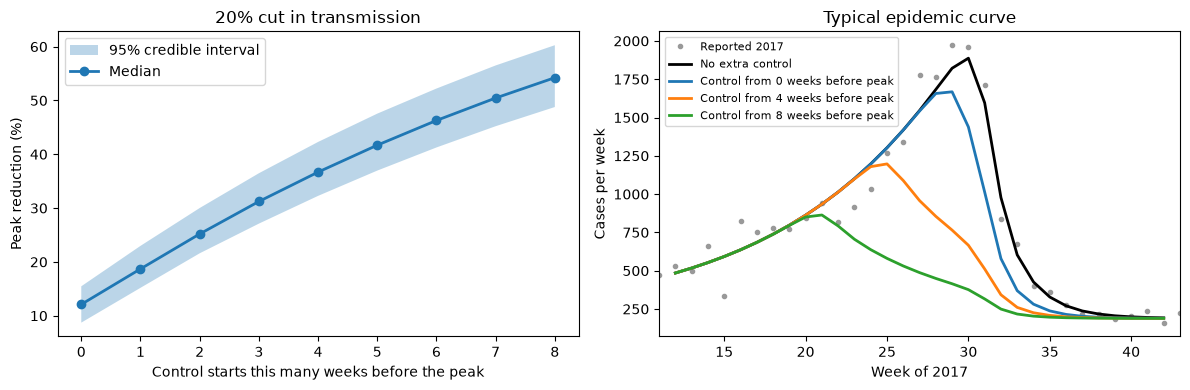

In [21]:
# Left: the answer with uncertainty. Right: what the epidemic curve looks like for a typical draw.
ks = np.arange(9)
bands = np.array([np.percentile(control_scenario(draws, k)[0], [2.5, 50, 97.5]) for k in ks])
p_typical = {name: np.median(post[:, i]) for i, name in enumerate(PARAM_NAMES)}
base_typ = simulate(p_typical)["expected_cases"]
peak_typ = FIRST_WEEK + base_typ.argmax()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.fill_between(ks, bands[:, 0], bands[:, 2], alpha=0.3, label="95% credible interval")
ax1.plot(ks, bands[:, 1], "o-", lw=2, label="Median")
ax1.set_xlabel("Control starts this many weeks before the peak")
ax1.set_ylabel("Peak reduction (%)"); ax1.set_title("20% cut in transmission"); ax1.legend()

ax2.plot(cases["week"], cases["cases"], "o", ms=3, color="0.6", label="Reported 2017")
ax2.plot(FIRST_WEEK + np.arange(len(base_typ)), base_typ, "k-", lw=2, label="No extra control")
for k in (0, 4, 8):
    ctrl = simulate(p_typical, {"cut": 0.2, "start": peak_typ - k, "weeks": np.inf})["expected_cases"]
    ax2.plot(FIRST_WEEK + np.arange(len(ctrl)), ctrl, lw=2, label=f"Control from {k} weeks before peak")
ax2.set_xlim(FIRST_WEEK - 1, LAST_WEEK + 1)
ax2.set_xlabel("Week of 2017"); ax2.set_ylabel("Cases per week"); ax2.set_title("Typical epidemic curve"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.3 Sensitivity analysis

How much does the answer depend on the choices made? Three checks:
1. **Strength vs timing.** Cuts of 10–40%, each started 0–8 weeks before the peak.
2. **Campaign length.** A 20% cut started 4 weeks before the peak, lasting 2, 4 or 8 weeks, or for the rest of the season.
3. **The fixed infectious period.** The model is refitted with 5 and 8 days instead of 6.5, and the main result (20% cut, 4 weeks early) is recomputed.

A useful analytic result: a sustained cut $c$ stops the growth when $R_0(1 - c) < 1$, that is, when $c > c^* = 1 - 1/R_0$.

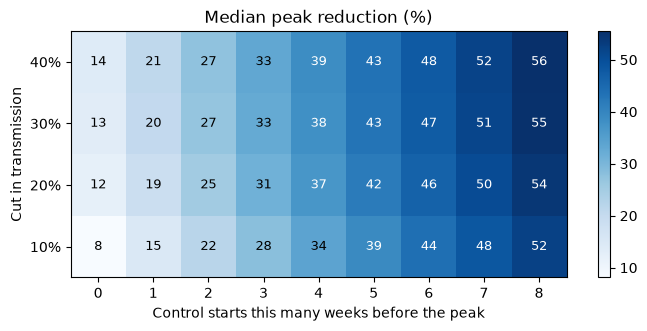

Critical cut c* = 1 - 1/R0: median 8.8% (95% CrI 7.4% to 10.2%)


,peak reduction %,cases averted %
campaign length,,
2 weeks,33.6 (32.0 to 34.5),15.7 (14.4 to 17.9)
4 weeks,36.7 (32.3 to 42.3),23.2 (21.2 to 26.9)
8 weeks,36.7 (32.3 to 42.3),26.7 (24.2 to 31.6)
rest of season,36.7 (32.3 to 42.3),26.9 (24.3 to 32.1)


In [22]:
cuts = [0.1, 0.2, 0.3, 0.4]
grid = np.array([[np.median(control_scenario(draws[:500], k, cut=c)[0]) for k in ks] for c in cuts])

fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(grid, aspect="auto", origin="lower", cmap="Blues")
ax.set_xticks(ks); ax.set_yticks(range(len(cuts))); ax.set_yticklabels([f"{c:.0%}" for c in cuts])
for i in range(len(cuts)):
    for j in ks:
        ax.text(j, i, f"{grid[i, j]:.0f}", ha="center", va="center", color="white" if grid[i, j] > 35 else "black", fontsize=9)
ax.set_xlabel("Control starts this many weeks before the peak"); ax.set_ylabel("Cut in transmission")
ax.set_title("Median peak reduction (%)"); fig.colorbar(im, ax=ax); plt.show()

critical = 100 * (1 - 1 / R0)
print(f"Critical cut c* = 1 - 1/R0: median {np.median(critical):.1f}% (95% CrI {np.percentile(critical, 2.5):.1f}% to {np.percentile(critical, 97.5):.1f}%)")

length_rows = []
for weeks in (2, 4, 8, np.inf):
    red, shift, averted = control_scenario(draws, 4, duration=weeks)
    length_rows.append({"campaign length": "rest of season" if np.isinf(weeks) else f"{weeks} weeks",
                        "peak reduction %": fmt(red), "cases averted %": fmt(averted)})
display(pd.DataFrame(length_rows).set_index("campaign length"))

In [23]:
# Refit with a different infectious period, then recompute the main result (20% cut, 4 weeks early).
# GAMMA is read by the model functions at run time, so it is changed here and restored afterwards.
gamma_rows = []
try:
    for days in (5.0, 6.5, 8.0):
        GAMMA = 7 / days
        if days == INFECTIOUS_DAYS:
            fit_g = fit                                     # the main fit already uses 6.5 days
        else:
            start_g = START.copy(); start_g[0] = np.median(R0) * GAMMA      # same R0 guess, new gamma
            fit_g = calibrate(obs, start_g, np.random.default_rng(SEED + 5))
            assert (fit_g["rhat"] < 1.1).all(), "refit did not converge"
        R0_g = fit_g["flat"][:, 0] / GAMMA
        sub = fit_g["flat"][np.random.default_rng(SEED + 6).choice(len(fit_g["flat"]), 2000, replace=False)]
        red, _, _ = control_scenario(sub, 4)
        gamma_rows.append({"infectious period (days)": days,
                           "R0 (median)": f"{np.median(R0_g):.3f}",
                           "peak reduction %, 20% cut 4 weeks early": fmt(red)})
finally:
    GAMMA = 7 / INFECTIOUS_DAYS                             # always restore the main value
display(pd.DataFrame(gamma_rows).set_index("infectious period (days)"))

,R0 (median),"peak reduction %, 20% cut 4 weeks early"
infectious period (days),,
5.0,1.075,37.3 (32.1 to 42.7)
6.5,1.096,36.8 (32.2 to 42.1)
8.0,1.117,36.6 (31.7 to 41.5)


### 5.4 Performance: vectorised simulation

Every function takes NumPy arrays of parameters, so thousands of epidemics are solved in one call instead of a Python loop. The cell below times both approaches on the same 100 posterior draws and checks that they give identical results.

In [24]:
d100 = draws[:100]
t0 = time.perf_counter()
looped = np.column_stack([simulate(to_params(d100[i:i + 1]))["expected_cases"][:, 0] for i in range(len(d100))])
t_loop = time.perf_counter() - t0
t0 = time.perf_counter()
vectorised = simulate(to_params(d100))["expected_cases"]
t_vec = time.perf_counter() - t0
assert np.allclose(looped, vectorised), "the vectorised and looped results differ"
print(f"Loop over 100 draws: {t_loop:.2f} s | one vectorised call: {t_vec:.3f} s | "
      f"speed-up {t_loop / t_vec:.0f}x (identical results)")

Loop over 100 draws: 1.52 s | one vectorised call: 0.017 s | speed-up 91x (identical results)


### 5.5 Reference values for the web demo

The web demo (`docs/index.html`) runs the same model in the browser on 200 posterior draws. This cell picks those draws (seed `SEED + 7`), rounds them exactly as they are stored in `docs/script.js`, and computes the demo's default scenario: a 20% cut starting 4 weeks before the peak, for the rest of the season. The demo must reproduce these values within ±0.1 percentage points, and it prints the same fingerprint, which shows that both use the same draws.

In [25]:
# Pick 200 posterior draws for the web demo and compute the demo's reference value
rng_demo = np.random.default_rng(SEED + 7)
demo = post[rng_demo.choice(len(post), size=200, replace=False)]
demo = np.column_stack([demo[:, 0].round(5), demo[:, 1].round(5), demo[:, 2].round(4),   # beta, delta, tau
                        demo[:, 3].round(2), demo[:, 4].round(2), demo[:, 5].round(2)])  # I0, bg, k
red, shift, averted = control_scenario(demo, 4)        # demo defaults: 20% cut, 4 weeks early, rest of season
print("Web demo reference (these 200 draws; 20% cut starting 4 weeks before the peak):")
print(f"  peak reduction {fmt(red)} %  |  peak shift {np.median(shift):+.0f} weeks  |  cases averted {fmt(averted)} %")
print("  fingerprint (mean beta, delta, tau, I0, bg):", " ".join(f"{m:.4f}" for m in demo[:, :5].mean(axis=0)))

Web demo reference (these 200 draws; 20% cut starting 4 weeks before the peak):
  peak reduction 37.0 (31.0 to 41.1) %  |  peak shift -5 weeks  |  cases averted 26.7 (24.4 to 31.6) %
  fingerprint (mean beta, delta, tau, I0, bg): 1.1805 0.5338 31.8019 239.2930 191.4641


## 6. Discussion and limitations

**What the results mean.** The calibrated model reproduces the 2017 Colombo epidemic well: 97% of the weeks fall inside the 95% predictive band. Before early August, transmission was only just above the epidemic threshold (R₀ ≈ 1.10). Around week 32 it roughly halved (δ ≈ 0.53, so R fell to about 0.51), and that ended the epidemic. Because R₀ was so close to 1, any sustained cut larger than c* = 1 − 1/R₀ ≈ 8.8% stops the growth as soon as it starts. So **when** control starts matters far more than **how strong** it is.
- A 20% cut starting 4 weeks before the peak lowers the peak by 36.7% (95% CrI 32.3–42.3%) and brings it about 5 weeks earlier.
- Even a 40% cut started at the peak lowers it by only about 14%.
- Each extra week of early action lowers the peak by about 4–7 more percentage points.
- A campaign of 4 weeks or more gives the full benefit, because the natural August drop takes over after that.

**Main assumptions and their effect.**
- *Infectious period fixed at 6.5 days.* Refitting with 5 or 8 days changes the main result by less than 1 percentage point (37.3% and 36.6%). This is because the data fix the weekly growth rate, not γ and R₀ separately.
- *Every infection is a reported case.* Dengue has many unreported infections. If only a small share were reported, immunity would build faster than the model assumes, and the effect of control could be different.
- *One well-mixed population.* Colombo is treated as a single group, so local hot spots are ignored.
- *Control is a constant cut in β.* Real fogging and clean-up campaigns vary in strength and coverage, so the 20% cut is a scenario, not an estimate.

**Limitations.**
- "k weeks before the peak" uses hindsight. In a real season, nobody knows the peak week in advance.
- Mosquitoes, rainfall and the four dengue serotypes are not modelled directly, and the August drop is assumed to happen in every scenario.
- The fit covers one district and one season, so the numbers should not be applied directly to other years or places.

**What I would do next.**
- Replace "weeks before the peak" with a realistic trigger, such as starting control when cases rise for three weeks in a row, and test how early that trigger fires.
- Add a human–mosquito model driven by rainfall, so the August drop is explained rather than fitted.
- Fit several seasons (for example 2017–2019) to check whether the timing result holds in other years.

**Web demo reference value:** with its default settings (a 20% cut starting 4 weeks before the peak, for the rest of the season), the web demo reproduces the 37.0% peak reduction and 26.7% of cases averted from section 5.5, within ±0.1 percentage points.

## 7. References

[1] Epidemiology Unit, Ministry of Health, Sri Lanka, "Weekly Epidemiological Report." [Online]. Available: https://www.epid.gov.lk. Compiled in T. S. Talagala, *denguedatahub: A Tidy Format Datasets of Dengue by Country*, R package v4.1.2. [Online]. Available: https://github.com/thiyangt/denguedatahub

[2] L. B. Carrington and C. P. Simmons, "Human to mosquito transmission of dengue viruses," *Frontiers in Immunology*, vol. 5, art. no. 290, 2014, doi: 10.3389/fimmu.2014.00290.

[3] Department of Census and Statistics, Sri Lanka, "Mid-year population estimates by district and sex, 2014–2024." [Online]. Available: https://www.statistics.gov.lk/Resource/en/Population/Vital_Statistics/Mid-year_population_by_district_and_sex_2014_2024.pdf

[4] W. O. Kermack and A. G. McKendrick, "A contribution to the mathematical theory of epidemics," *Proceedings of the Royal Society A*, vol. 115, pp. 700–721, 1927, doi: 10.1098/rspa.1927.0118.

[5] N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller and E. Teller, "Equation of state calculations by fast computing machines," *Journal of Chemical Physics*, vol. 21, no. 6, pp. 1087–1092, 1953, doi: 10.1063/1.1699114.

[6] G. O. Roberts, A. Gelman and W. R. Gilks, "Weak convergence and optimal scaling of random walk Metropolis algorithms," *Annals of Applied Probability*, vol. 7, no. 1, pp. 110–120, 1997, doi: 10.1214/aoap/1034625254.

[7] A. Gelman and D. B. Rubin, "Inference from iterative simulation using multiple sequences," *Statistical Science*, vol. 7, no. 4, pp. 457–472, 1992, doi: 10.1214/ss/1177011136.